In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("All Libraries Installed Successfully ✅")

All Libraries Installed Successfully ✅


In [15]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")

In [16]:
df = pd.read_csv("creditcard.csv")

In [17]:

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [18]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

Rows : 284807
Columns : 31


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [20]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [21]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 1081


In [22]:
df = df.drop_duplicates()

print("New Shape:", df.shape)

New Shape: (283726, 31)


In [23]:
df["Class"].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

In [24]:
df["Class"].value_counts(normalize=True) * 100

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64

In [25]:
df = df.drop_duplicates()

print("New Shape :", df.shape)

New Shape : (283726, 31)


In [26]:
df["Class"].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

In [27]:
(df["Class"].value_counts(normalize=True) * 100).round(2)

Class
0    99.83
1     0.17
Name: proportion, dtype: float64

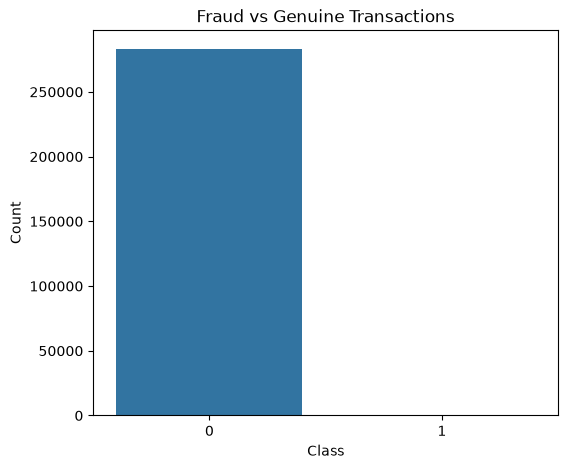

In [28]:
plt.figure(figsize=(6,5))

sns.countplot(x="Class", data=df)

plt.title("Fraud vs Genuine Transactions")

plt.xlabel("Class")

plt.ylabel("Count")

plt.show()

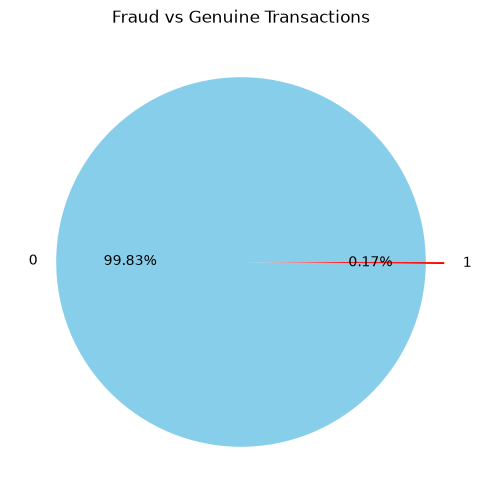

In [29]:
plt.figure(figsize=(6,6))

df["Class"].value_counts().plot(
    kind="pie",
    autopct="%1.2f%%",
    colors=["skyblue", "red"],
    explode=[0,0.1]
)

plt.title("Fraud vs Genuine Transactions")

plt.ylabel("")

plt.show()

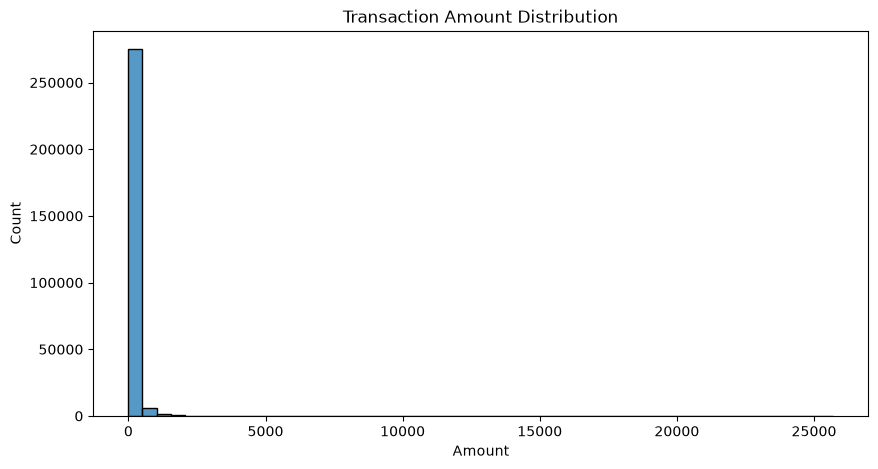

In [30]:
plt.figure(figsize=(10,5))

sns.histplot(df["Amount"], bins=50)

plt.title("Transaction Amount Distribution")

plt.show()

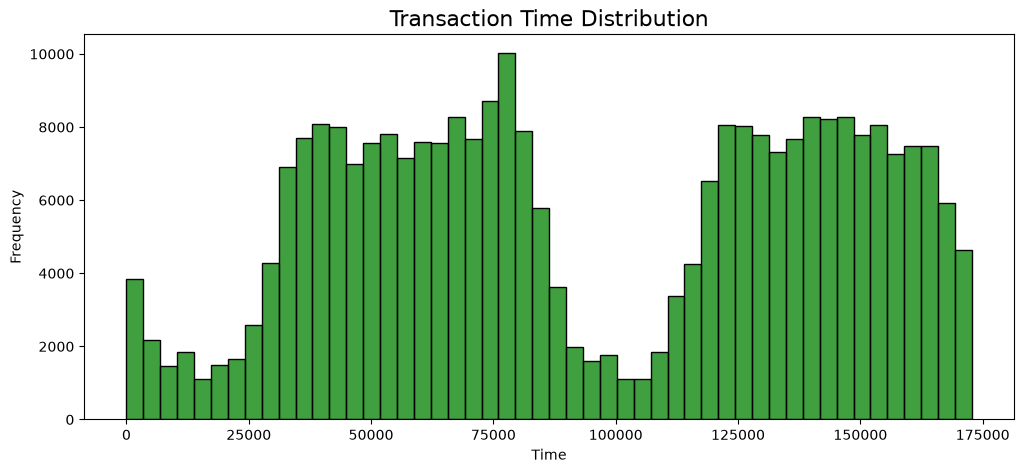

In [31]:
plt.figure(figsize=(12,5))

sns.histplot(df["Time"], bins=50, color="green")

plt.title("Transaction Time Distribution", fontsize=16)
plt.xlabel("Time")
plt.ylabel("Frequency")

plt.show()

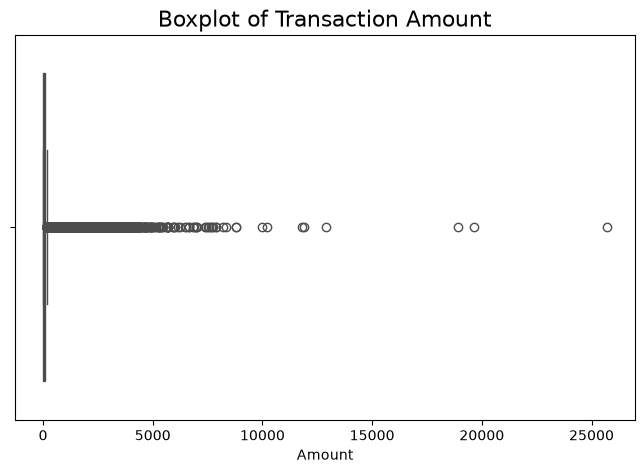

In [32]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Amount"], color="orange")

plt.title("Boxplot of Transaction Amount", fontsize=16)

plt.show()

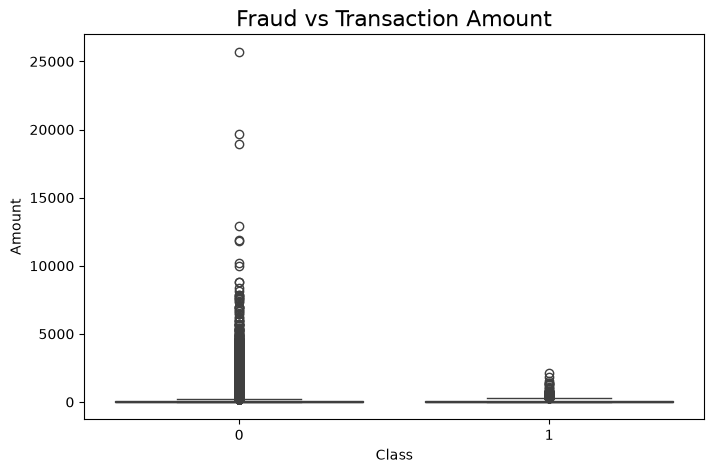

In [33]:
plt.figure(figsize=(8,5))

sns.boxplot(x="Class", y="Amount", data=df)

plt.title("Fraud vs Transaction Amount", fontsize=16)

plt.show()

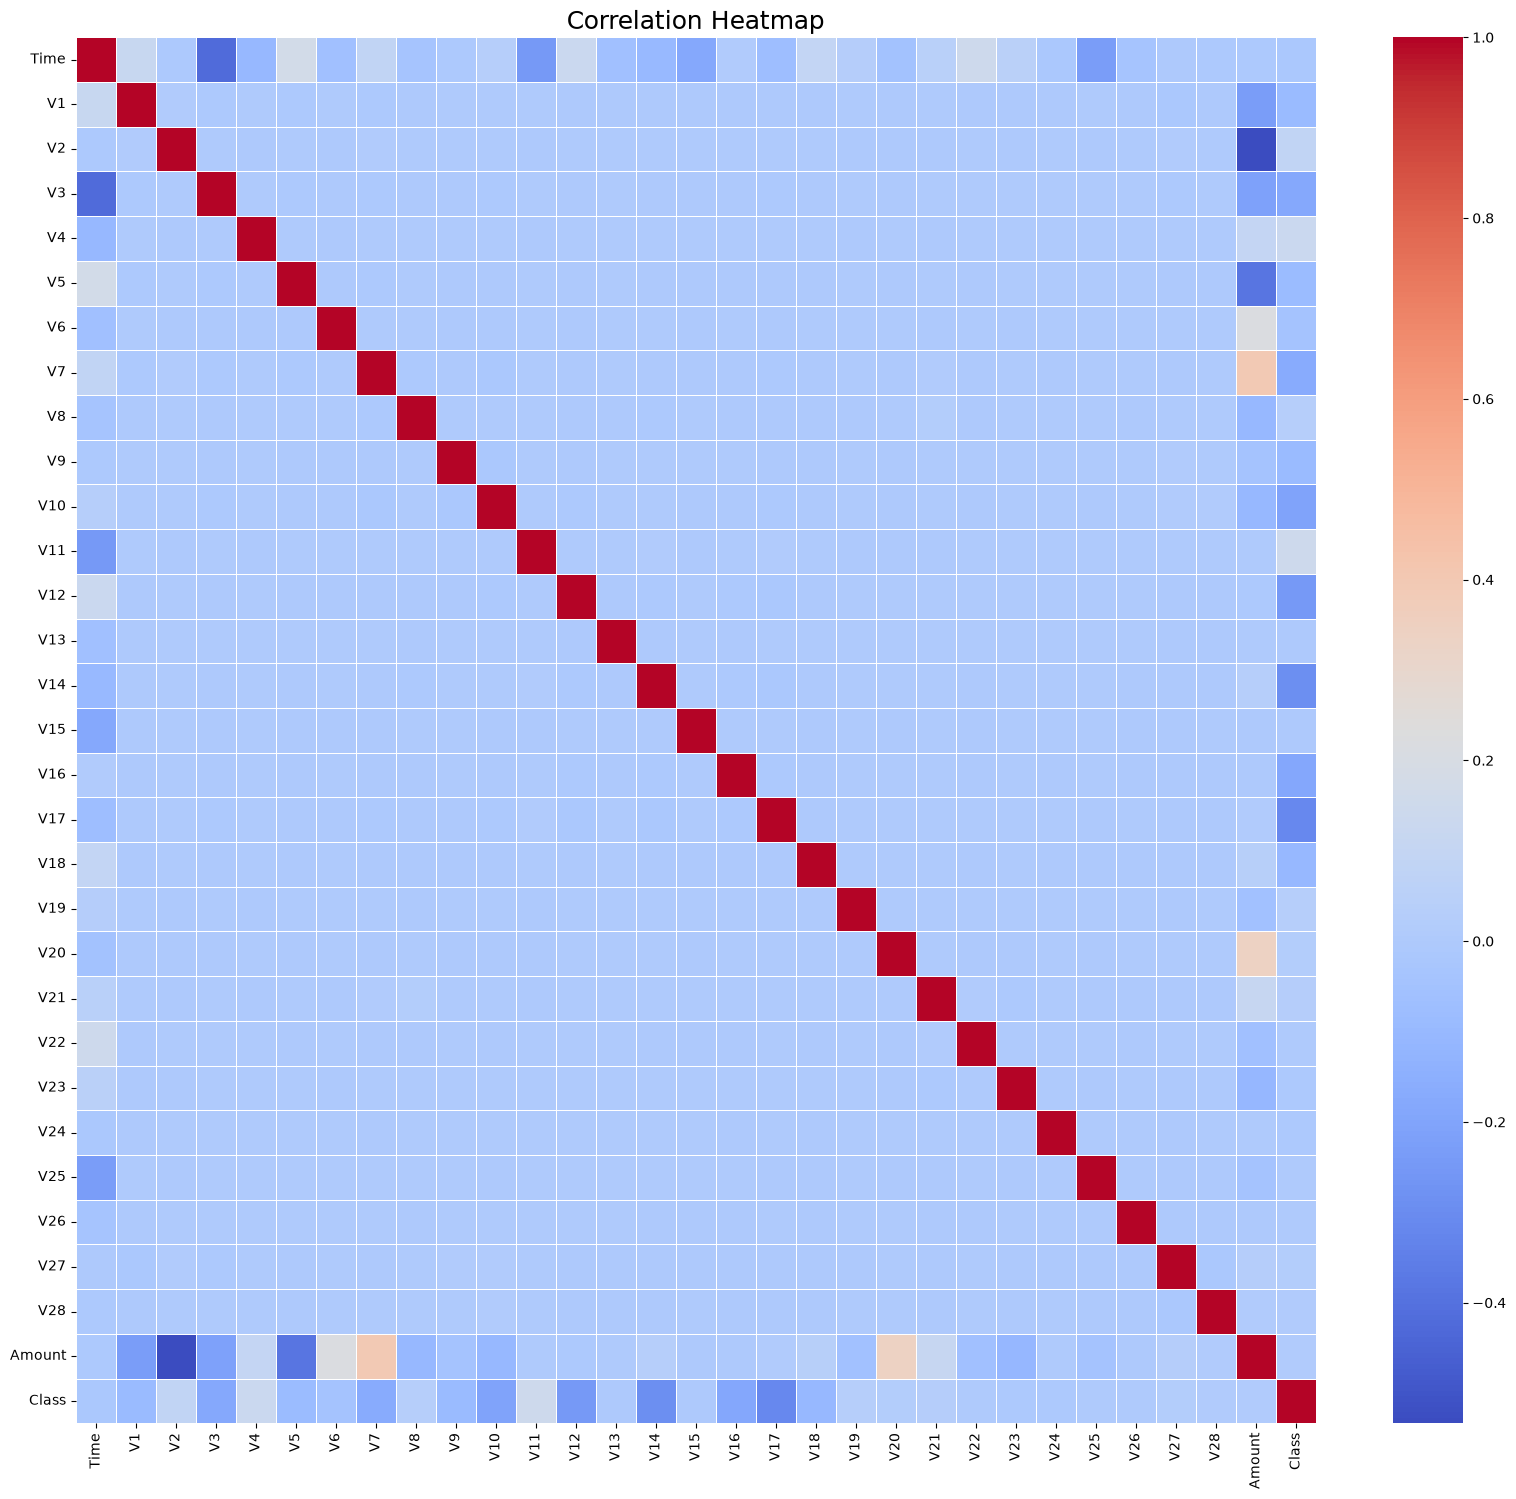

In [34]:
plt.figure(figsize=(20,18))

corr = df.corr()

sns.heatmap(corr,
            cmap="coolwarm",
            linewidths=0.5)

plt.title("Correlation Heatmap", fontsize=18)

plt.show()

In [35]:
corr = df.corr()["Class"].sort_values(ascending=False)

print(corr.head(10))

Class    1.000000
V11      0.149067
V4       0.129326
V2       0.084624
V19      0.033631
V8       0.033068
V21      0.026357
V27      0.021892
V20      0.021486
V28      0.009682
Name: Class, dtype: float64


In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df["Amount"] = scaler.fit_transform(df[["Amount"]])

df["Time"] = scaler.fit_transform(df[["Time"]])

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.996823,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0.244200,0
1,-1.996823,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,-0.342584,0
2,-1.996802,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,1.158900,0
3,-1.996802,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0.139886,0
4,-1.996781,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,-0.073813,0


In [37]:
X = df.drop("Class", axis=1)

y = df["Class"]

print("Features Shape :", X.shape)
print("Target Shape :", y.shape)

Features Shape : (283726, 30)
Target Shape : (283726,)


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data :", X_train.shape)
print("Testing Data :", X_test.shape)

Training Data : (226980, 30)
Testing Data : (56746, 30)


In [39]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE")
print(y_train.value_counts())

print("\nAfter SMOTE")
print(y_train_smote.value_counts())

Before SMOTE
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE
Class
0    226602
1    226602
Name: count, dtype: int64


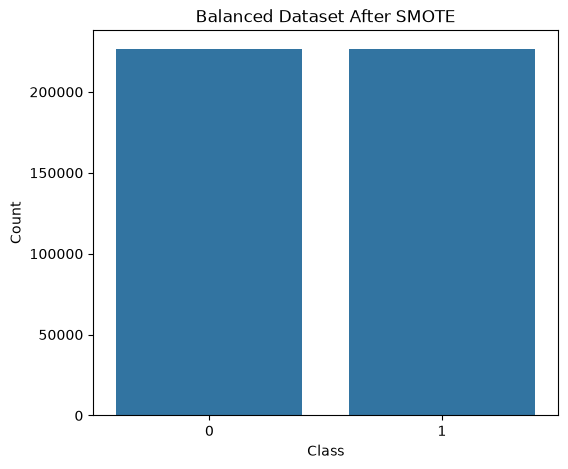

In [40]:
plt.figure(figsize=(6,5))

sns.countplot(x=y_train_smote)

plt.title("Balanced Dataset After SMOTE")

plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

In [42]:
lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train_smote, y_train_smote)

y_pred_lr = lr.predict(X_test)

In [43]:
print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision :", precision_score(y_test, y_pred_lr))
print("Recall :", recall_score(y_test, y_pred_lr))
print("F1 Score :", f1_score(y_test, y_pred_lr))

Accuracy : 0.9737250202657456
Precision : 0.05313700384122919
Recall : 0.8736842105263158
F1 Score : 0.10018105009052504


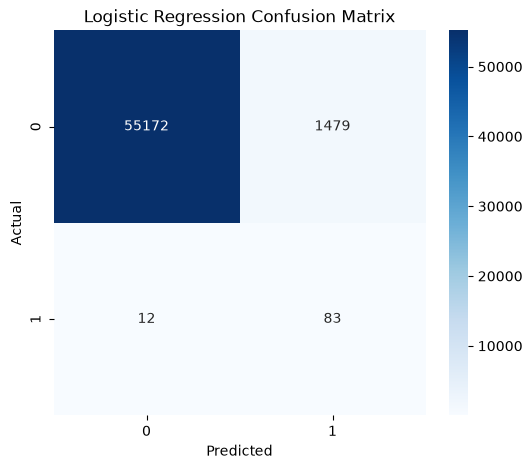

In [44]:
plt.figure(figsize=(6,5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_lr),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [45]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746



In [46]:
dt = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt.fit(X_train_smote, y_train_smote)

y_pred_dt = dt.predict(X_test)

In [47]:
print("Accuracy :", accuracy_score(y_test, y_pred_dt))
print("Precision :", precision_score(y_test, y_pred_dt))
print("Recall :", recall_score(y_test, y_pred_dt))
print("F1 Score :", f1_score(y_test, y_pred_dt))

Accuracy : 0.9840869841046065
Precision : 0.07828810020876827
Recall : 0.7894736842105263
F1 Score : 0.14245014245014245


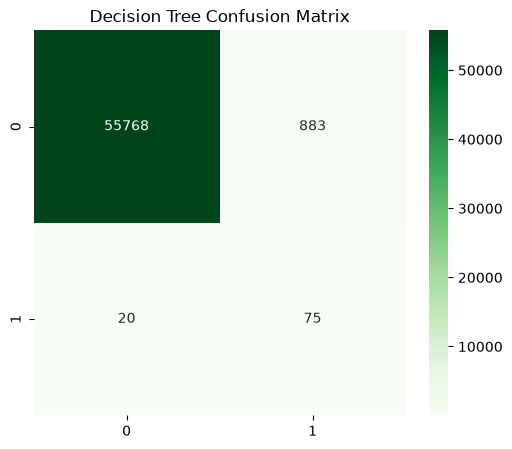

In [48]:
plt.figure(figsize=(6,5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_dt),
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Decision Tree Confusion Matrix")

plt.show()

In [55]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train_smote, y_train_smote)

y_pred_rf = rf.predict(X_test)

In [54]:
rf = RandomForestClassifier(
    n_estimators=20,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_smote, y_train_smote)

y_pred_rf = rf.predict(X_test)

In [56]:
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision :", precision_score(y_test, y_pred_rf))
print("Recall :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))

Accuracy : 0.9994713283755683
Precision : 0.9113924050632911
Recall : 0.7578947368421053
F1 Score : 0.8275862068965517


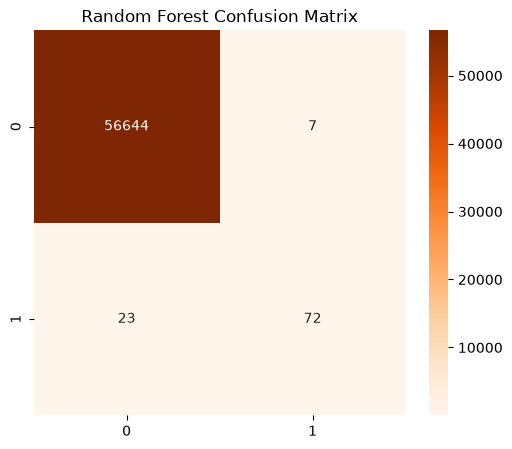

In [57]:
plt.figure(figsize=(6,5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_rf),
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Random Forest Confusion Matrix")

plt.show()

<Figure size 800x600 with 0 Axes>

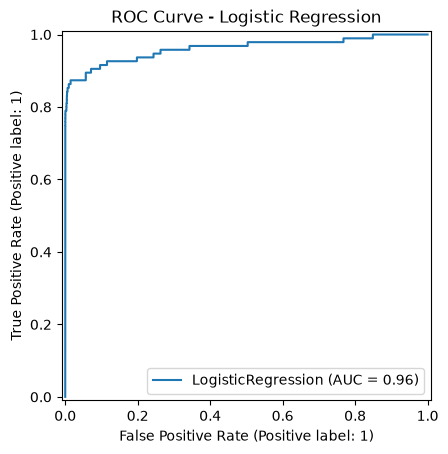

In [58]:
plt.figure(figsize=(8,6))

RocCurveDisplay.from_estimator(lr, X_test, y_test)

plt.title("ROC Curve - Logistic Regression")

plt.show()

In [59]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.973725,0.053137,0.873684,0.100181
1,Decision Tree,0.984087,0.078288,0.789474,0.142450
2,Random Forest,0.999471,0.911392,0.757895,0.827586


In [60]:
results.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.999471,0.911392,0.757895,0.827586
1,Decision Tree,0.984087,0.078288,0.789474,0.142450
0,Logistic Regression,0.973725,0.053137,0.873684,0.100181


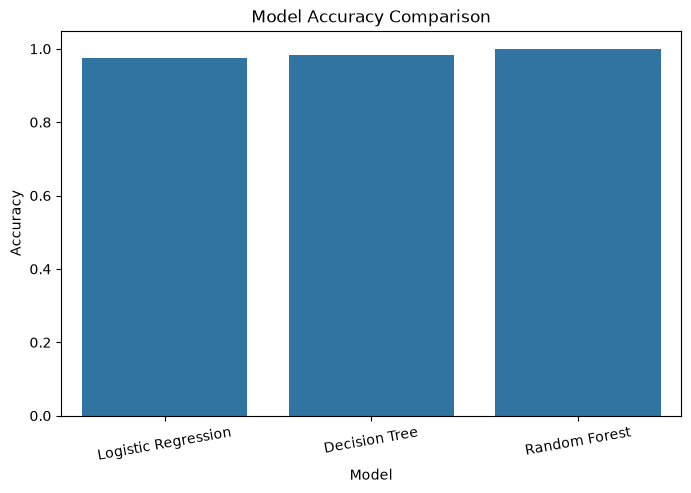

In [61]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")

plt.xticks(rotation=10)

plt.show()

In [62]:
best_model = results.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]

print("Best Model:")
print(best_model)

Best Model:
Model        Random Forest
Accuracy          0.999471
Precision         0.911392
Recall            0.757895
F1 Score          0.827586
Name: 2, dtype: object


In [63]:
import joblib
import os

In [64]:
os.makedirs("model", exist_ok=True)

In [65]:
joblib.dump(rf, "model/fraud_model.pkl")

print("Model Saved Successfully ✅")

Model Saved Successfully ✅


In [66]:
joblib.dump(scaler, "model/scaler.pkl")

print("Scaler Saved Successfully ✅")

Scaler Saved Successfully ✅


In [67]:
model = joblib.load("model/fraud_model.pkl")

print(model)

RandomForestClassifier(random_state=42)


In [68]:
loaded_scaler = joblib.load("model/scaler.pkl")

In [69]:
sample = X_test.iloc[[0]]

prediction = model.predict(sample)

print("Prediction :", prediction)

Prediction : [0]


In [70]:
probability = model.predict_proba(sample)

print(probability)

[[1. 0.]]


In [71]:
def predict_transaction(data):

    prediction = model.predict(data)

    probability = model.predict_proba(data)

    if prediction[0] == 0:

        print("✅ Genuine Transaction")

    else:

        print("🚨 Fraud Transaction")

    print("Fraud Probability :", probability[0][1])

In [72]:
predict_transaction(sample)

✅ Genuine Transaction
Fraud Probability : 0.0


In [73]:
predictions = model.predict(X_test)

result = X_test.copy()

result["Actual"] = y_test.values

result["Prediction"] = predictions

result.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Actual,Prediction
86568,-0.705990,1.228821,-0.063408,0.274145,0.647465,-0.048135,0.372073,-0.224231,0.079939,0.640759,...,-0.083779,-0.151661,-0.700372,0.598550,0.491409,0.002989,0.001782,-0.307400,0,0
251557,1.275941,-0.203154,1.176678,-0.759595,-0.518472,0.629649,-0.721675,0.638893,0.243377,-0.157488,...,1.206754,-0.082753,0.508386,-0.710906,-0.234510,0.379640,0.261351,-0.345579,0,0
20232,-1.346436,-1.672836,1.401297,1.503940,2.175491,0.699791,1.062139,1.114364,-0.535822,-0.252983,...,-0.408743,-0.280083,-0.846468,-0.155456,-0.062383,0.007777,0.113900,0.011211,0,0
68952,-0.876311,0.819379,-1.124913,0.515025,0.513945,-1.009048,0.488484,-0.580672,0.187686,-0.999142,...,-0.168061,-0.198732,-0.337408,0.238538,-0.289454,0.038214,0.058407,0.557220,0,0
191852,0.729091,2.009701,0.105635,-1.752759,0.588312,0.374801,-0.637884,0.009260,-0.129487,0.492619,...,0.357394,-0.013472,-0.446920,0.111522,0.642944,-0.036998,-0.043404,-0.347696,0,0


In [74]:
result.to_csv(
    "Prediction_Result.csv",
    index=False
)

print("Prediction File Saved Successfully ✅")

Prediction File Saved Successfully ✅


In [75]:
importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": rf.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(10)

,Feature,Importance
14,V14,0.195029
10,V10,0.115016
12,V12,0.098714
4,V4,0.094295
17,V17,0.091678
16,V16,0.056576
11,V11,0.056238
3,V3,0.055112
2,V2,0.038038
9,V9,0.025604


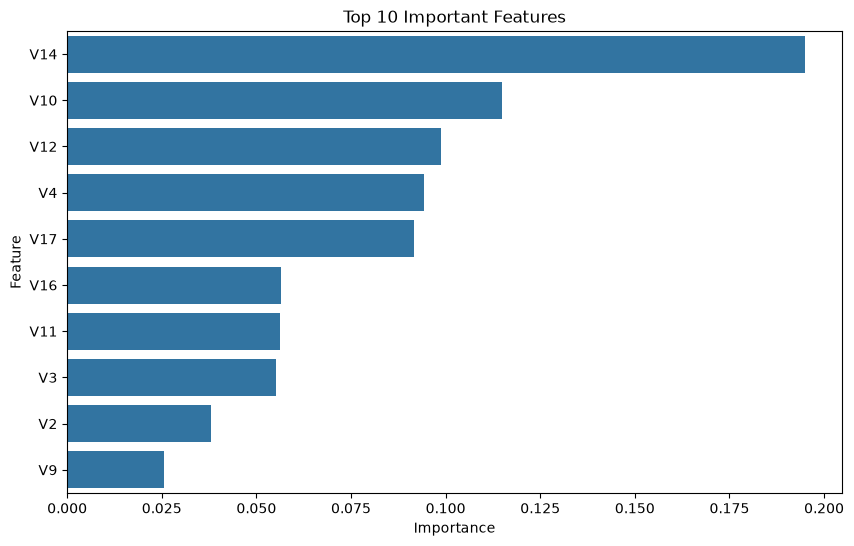

In [76]:
plt.figure(figsize=(10,6))

sns.barplot(

    data=importance.head(10),

    x="Importance",

    y="Feature"

)

plt.title("Top 10 Important Features")

plt.show()